In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
import numpy as np
import cv2
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DATA_DIR = 'data'
HEIGHT, WIDTH = 64, 96
BATCH_SIZE = 32
N_EPOCHS = 30
PATIENCE = 5
MIN_DELTA = 0.001
CLASSES = ['Fish', 'Flower', 'Gravel', 'Sugar']
CHECKPOINT = 'cloud_cnn_best.pt'
print('Устройство:', device)

Устройство: cpu


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
for candidate in [DATA_DIR, 'CNN/data', '/tmp/cloud_hw_run/data']:
    try:
        with open(f'{candidate}/train.csv') as file:
            pass
        DATA_DIR = candidate
        break
    except FileNotFoundError:
        continue
else:
    !gdown 1leoj71B_D_paBLC1uP5EKcnR5lJFPovn -O dataset.zip
    !unzip -q -o dataset.zip -d {DATA_DIR}

records = {}
with open(f'{DATA_DIR}/train.csv') as file:
    next(file)
    for line in file:
        image_class, rle = line.strip().split(',', 1)
        image_id, class_name = image_class.split('_')
        if image_id not in records:
            records[image_id] = [''] * len(CLASSES)
        records[image_id][CLASSES.index(class_name)] = rle.strip('"')

image_ids = list(records)
image = cv2.imread(f'{DATA_DIR}/train_images/{image_ids[0]}')
assert image is not None, 'Проверьте путь к train_images'
SOURCE_HEIGHT, SOURCE_WIDTH = image.shape[:2]
rows = [i * SOURCE_HEIGHT // HEIGHT for i in range(HEIGHT)]
cols = [i * SOURCE_WIDTH // WIDTH for i in range(WIDTH)]
pixel_indices = np.array([[row + col * SOURCE_HEIGHT for col in cols] for row in rows])
print('Изображений:', len(image_ids))
print('Исходный размер:', SOURCE_HEIGHT, SOURCE_WIDTH)
print('Размер для обучения:', HEIGHT, WIDTH)
print('Масок по классам:', [sum(records[name][c] != '' for name in image_ids) for c in range(4)])

Изображений: 5546
Исходный размер: 1400 2100
Размер для обучения: 64 96
Масок по классам: [2781, 2365, 2939, 3751]


## Данные

In [3]:
def decode_rle(rle):
    mask = np.zeros(SOURCE_HEIGHT * SOURCE_WIDTH, dtype=np.uint8)
    if rle:
        values = [int(value) for value in rle.split()]
        for start, length in zip(values[0::2], values[1::2]):
            mask[start - 1:start - 1 + length] = 1
    return mask[pixel_indices]

images, masks = [], []
for image_id in tqdm(image_ids, desc='Подготовка данных'):
    image = cv2.imread(f'{DATA_DIR}/train_images/{image_id}')
    assert image is not None, image_id
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)[rows][:, cols]
    images.append(np.array([image[:, :, c] for c in range(3)]))
    masks.append(np.array([decode_rle(rle) for rle in records[image_id]]))

rng = np.random.RandomState(42)
indices = rng.permutation(len(image_ids))
train_end = int(0.8 * len(indices))
val_end = int(0.9 * len(indices))
train_indices = indices[:train_end]
val_indices = indices[train_end:val_end]
test_indices = indices[val_end:]

class CloudDataset:
    def __init__(self, indices, augment=False):
        self.indices = indices
        self.augment = augment

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        index = self.indices[index]
        image, mask = images[index], masks[index]
        if self.augment and rng.permutation(2)[0] == 1:
            image, mask = image[:, :, ::-1], mask[:, :, ::-1]
        if self.augment and rng.permutation(2)[0] == 1:
            image, mask = image[:, ::-1, :], mask[:, ::-1, :]
        return torch.tensor(image.copy()).float() / 255, torch.tensor(mask.copy()).float()

train_dataset = CloudDataset(train_indices, augment=True)
val_dataset = CloudDataset(val_indices)
test_dataset = CloudDataset(test_indices)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
print('Train / validation / test:', len(train_dataset), len(val_dataset), len(test_dataset))


Подготовка данных:   0%|          | 0/5546 [00:00<?, ?it/s]


Подготовка данных:   0%|          | 14/5546 [00:00<00:40, 137.50it/s]


Подготовка данных:   1%|          | 28/5546 [00:00<00:40, 134.94it/s]


Подготовка данных:   1%|          | 42/5546 [00:00<00:40, 135.36it/s]


Подготовка данных:   1%|          | 56/5546 [00:00<00:40, 136.50it/s]

...


Подготовка данных:  99%|█████████▉| 5513/5546 [00:39<00:00, 142.64it/s]


Подготовка данных: 100%|█████████▉| 5528/5546 [00:39<00:00, 140.43it/s]


Подготовка данных: 100%|█████████▉| 5543/5546 [00:39<00:00, 141.06it/s]


Подготовка данных: 100%|██████████| 5546/5546 [00:39<00:00, 141.11it/s]

Train / validation / test: 4436 555 555


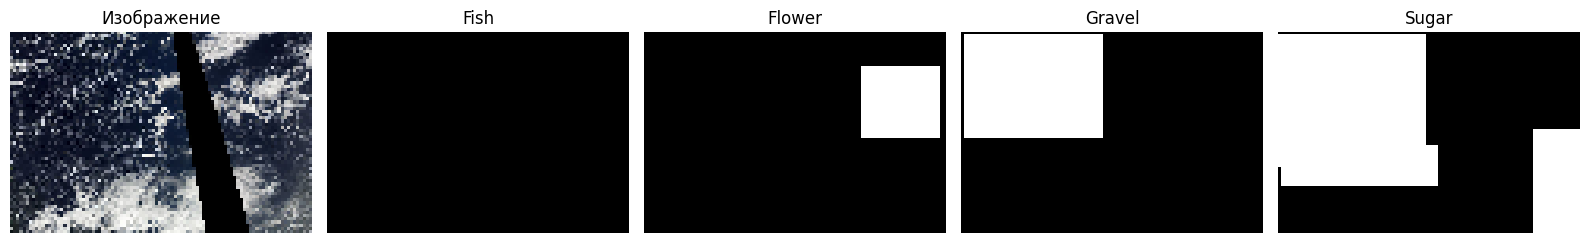

In [4]:
image, mask = val_dataset[0]
plt.figure(figsize=(16, 3))
plt.subplot(1, 5, 1)
rgb = np.zeros((HEIGHT, WIDTH, 3), dtype=np.float32)
for c in range(3):
    rgb[:, :, c] = image[c].numpy()
plt.imshow(rgb)
plt.title('Изображение')
plt.axis('off')
for c, class_name in enumerate(CLASSES):
    plt.subplot(1, 5, c + 2)
    plt.imshow(mask[c].numpy(), cmap='gray', vmin=0, vmax=1)
    plt.title(class_name)
    plt.axis('off')
plt.tight_layout()
plt.show()

## Свёрточная сеть

In [4]:
def conv_block(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, 3, padding=1),
        nn.BatchNorm2d(out_channels), nn.ReLU(),
        nn.Conv2d(out_channels, out_channels, 3, padding=1),
        nn.BatchNorm2d(out_channels), nn.ReLU(),
    )

def upsample(x):
    return x[:, :, [i // 2 for i in range(x.size(2) * 2)], :][:, :, :, [i // 2 for i in range(x.size(3) * 2)]]

class CloudCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc1 = conv_block(3, 16)
        self.enc2 = conv_block(16, 32)
        self.center = conv_block(32, 64)
        self.pool = nn.MaxPool2d(2)
        self.dec2 = conv_block(64 + 32, 32)
        self.dec1 = conv_block(32 + 16, 16)
        self.output = nn.Conv2d(16, 8, 1)

    def forward(self, x):
        enc1 = self.enc1(x)
        enc2 = self.enc2(self.pool(enc1))
        x = self.center(self.pool(enc2))
        x = self.dec2(torch.cat([upsample(x), enc2], dim=1))
        x = self.dec1(torch.cat([upsample(x), enc1], dim=1))
        return self.output(x).view(x.size(0), 2, 4, HEIGHT, WIDTH)

model = CloudCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=8, gamma=0.5)
print(model)
print('Параметров:', sum(p.numel() for p in model.parameters()))

CloudCNN(
  (enc1): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
  )
  (enc2): Sequential(
    (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
  )
  (center): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, tr

In [5]:
def loss_function(logits, target):
    probabilities = F.softmax(logits, dim=1)[:, 1]
    intersection = (probabilities * target).sum(dim=(0, 2, 3))
    denominator = probabilities.sum(dim=(0, 2, 3)) + target.sum(dim=(0, 2, 3))
    soft_dice = ((2 * intersection + 1) / (denominator + 1)).mean()
    return criterion(logits, target.to(torch.long)) + 1 - soft_dice

def dice_coefficient(prediction, target):
    intersection = (prediction * target).sum(dim=(2, 3))
    denominator = prediction.sum(dim=(2, 3)) + target.sum(dim=(2, 3))
    empty = (denominator == 0).float()
    return (2 * intersection + empty) / (denominator + empty)

def train_epoch(model, loader):
    model.train()
    total_loss, total_dice, total = 0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        loss = loss_function(logits, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        with torch.no_grad():
            prediction = (F.softmax(logits, dim=1)[:, 1] > 0.5).float()
            total_dice += dice_coefficient(prediction, y).sum().item()
        total_loss += loss.item() * x.size(0)
        total += x.size(0)
    return total_loss / total, total_dice / (total * 4)

def evaluate(model, loader, thresholds=0.5, min_areas=0.0):
    model.eval()
    total_loss, total, scores = 0, 0, []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            total_loss += loss_function(logits, y).item() * x.size(0)
            prediction = (F.softmax(logits, dim=1)[:, 1] > thresholds).float()
            areas = prediction.sum(dim=(2, 3), keepdim=True) / (HEIGHT * WIDTH)
            prediction = prediction * (areas >= min_areas).float()
            scores.append(dice_coefficient(prediction, y).cpu())
            total += x.size(0)
    scores = torch.cat(scores)
    return total_loss / total, scores.mean().item(), scores.mean(dim=0).numpy()

## Обучение

Сохраняем максимум validation Dice. Ранняя остановка срабатывает после пяти эпох без улучшения метрики хотя бы на 0.001. После обучения восстанавливаем сохранённые веса.

In [7]:
history = {'train_loss': [], 'val_loss': [], 'train_dice': [], 'val_dice': []}
best_dice, patience_dice, best_epoch, wait = -1, -1, 0, 0
for epoch in range(1, N_EPOCHS + 1):
    train_loss, train_dice = train_epoch(model, train_loader)
    val_loss, val_dice, _ = evaluate(model, val_loader)
    scheduler.step()
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_dice'].append(train_dice)
    history['val_dice'].append(val_dice)
    print(f'Эпоха {epoch:02d}: loss {train_loss:.4f} / {val_loss:.4f}, Dice {train_dice:.4f} / {val_dice:.4f}')
    if val_dice > best_dice:
        best_dice, best_epoch = val_dice, epoch
        torch.save({'model': model.state_dict(), 'epoch': best_epoch, 'val_dice': best_dice}, CHECKPOINT)
    if val_dice > patience_dice + MIN_DELTA:
        patience_dice, wait = val_dice, 0
    else:
        wait += 1
    if wait >= PATIENCE:
        print(f'Ранняя остановка на эпохе {epoch}')
        break

checkpoint = torch.load(CHECKPOINT, map_location=device)
model.load_state_dict(checkpoint['model'])
print(f'Лучшая эпоха: {best_epoch}, validation Dice: {best_dice:.4f}')

Эпоха 01: loss 1.1282 / 1.0016, Dice 0.2963 / 0.4057


Эпоха 02: loss 0.9402 / 0.9607, Dice 0.3722 / 0.4033


Эпоха 03: loss 0.9019 / 0.9583, Dice 0.3969 / 0.4100


Эпоха 04: loss 0.8929 / 0.9277, Dice 0.4073 / 0.4100


Эпоха 05: loss 0.8808 / 0.9998, Dice 0.4183 / 0.4186


...

Эпоха 12: loss 0.8413 / 1.0118, Dice 0.4470 / 0.3974


Эпоха 13: loss 0.8405 / 0.8537, Dice 0.4489 / 0.4580


Эпоха 14: loss 0.8391 / 0.8458, Dice 0.4539 / 0.4600


Эпоха 15: loss 0.8353 / 0.9214, Dice 0.4539 / 0.4592


Эпоха 16: loss 0.8341 / 0.8565, Dice 0.4533 / 0.4471
Ранняя остановка на эпохе 16
Лучшая эпоха: 11, validation Dice: 0.4616


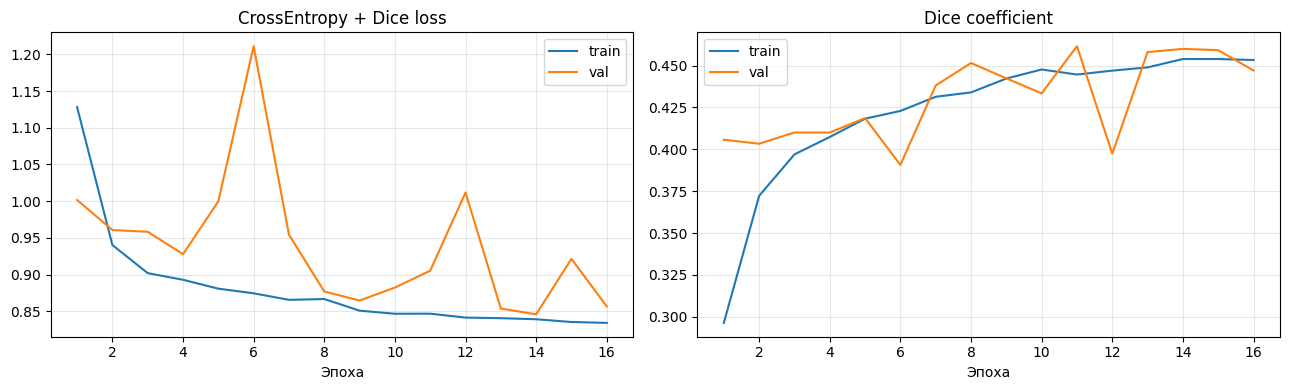

In [8]:
epochs = range(1, len(history['train_loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for split in ['train', 'val']:
    axes[0].plot(epochs, history[f'{split}_loss'], label=split)
    axes[1].plot(epochs, history[f'{split}_dice'], label=split)
axes[0].set_title('CrossEntropy + Dice loss')
axes[1].set_title('Dice coefficient')
for ax in axes:
    ax.set_xlabel('Эпоха')
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Оценка на отложенном тесте

In [6]:
checkpoint = torch.load(CHECKPOINT, map_location=device)
model.load_state_dict(checkpoint['model'])
best_epoch, best_dice = checkpoint['epoch'], checkpoint['val_dice']
model.eval()
probabilities, targets = [], []
with torch.no_grad():
    for x, y in val_loader:
        probabilities.append(F.softmax(model(x.to(device)), dim=1)[:, 1].cpu())
        targets.append(y)
probabilities, targets = torch.cat(probabilities), torch.cat(targets)
best_thresholds, best_areas, calibrated_scores = [], [], []
for c, class_name in enumerate(CLASSES):
    best_score, best_threshold, best_area = -1, 0.5, 0.0
    for threshold in [0.25, 0.35, 0.45, 0.5, 0.55, 0.65, 0.75, 0.85, 0.95, 1.0]:
        binary = (probabilities[:, c:c + 1] > threshold).float()
        areas = binary.sum(dim=(2, 3), keepdim=True) / (HEIGHT * WIDTH)
        for min_area in [0.0, 0.01, 0.05, 0.1]:
            prediction = binary * (areas >= min_area).float()
            scores = dice_coefficient(prediction, targets[:, c:c + 1])
            score = scores.sum().item() / scores.numel()
            if score > best_score:
                best_score, best_threshold, best_area = score, threshold, min_area
    best_thresholds.append(best_threshold)
    best_areas.append(best_area)
    calibrated_scores.append(best_score)
    print(f'{class_name}: порог={best_threshold:.2f}, мин. площадь={best_area:.2f}, validation Dice={best_score:.4f}')
thresholds = torch.tensor(best_thresholds, device=device).view(1, 4, 1, 1)
min_areas = torch.tensor(best_areas, device=device).view(1, 4, 1, 1)
calibrated_val_dice = sum(calibrated_scores) / 4
checkpoint['thresholds'], checkpoint['min_areas'] = best_thresholds, best_areas
torch.save(checkpoint, CHECKPOINT)
print(f'Validation Dice: {best_dice:.4f} при пороге 0.5; {calibrated_val_dice:.4f} после подбора параметров')

Fish: порог=0.75, мин. площадь=0.10, validation Dice=0.5864
Flower: порог=0.25, мин. площадь=0.05, validation Dice=0.6968
Gravel: порог=0.65, мин. площадь=0.10, validation Dice=0.5397
Sugar: порог=0.50, мин. площадь=0.10, validation Dice=0.5345
Validation Dice: 0.4616 при пороге 0.5; 0.5893 после подбора параметров


In [7]:
test_loss, test_dice, class_dice = evaluate(model, test_loader, thresholds, min_areas)
empty_scores = []
for _, target in test_loader:
    empty_scores.append(dice_coefficient(torch.zeros_like(target), target))
empty_dice = torch.cat(empty_scores).mean().item()
print(f'Лучшая эпоха: {best_epoch}')
print(f'Validation Dice после подбора параметров: {calibrated_val_dice:.4f}')
print(f'Test loss: {test_loss:.4f}')
print(f'Test Dice: {test_dice:.4f}')
print(f'Dice пустых масок: {empty_dice:.4f}')
for class_name, score in zip(CLASSES, class_dice):
    print(f'{class_name}: {score:.4f}')

Лучшая эпоха: 11
Validation Dice после подбора параметров: 0.5893
Test loss: 0.8971
Test Dice: 0.5896
Dice пустых масок: 0.4730
Fish: 0.5630
Flower: 0.6753
Gravel: 0.5736
Sugar: 0.5463


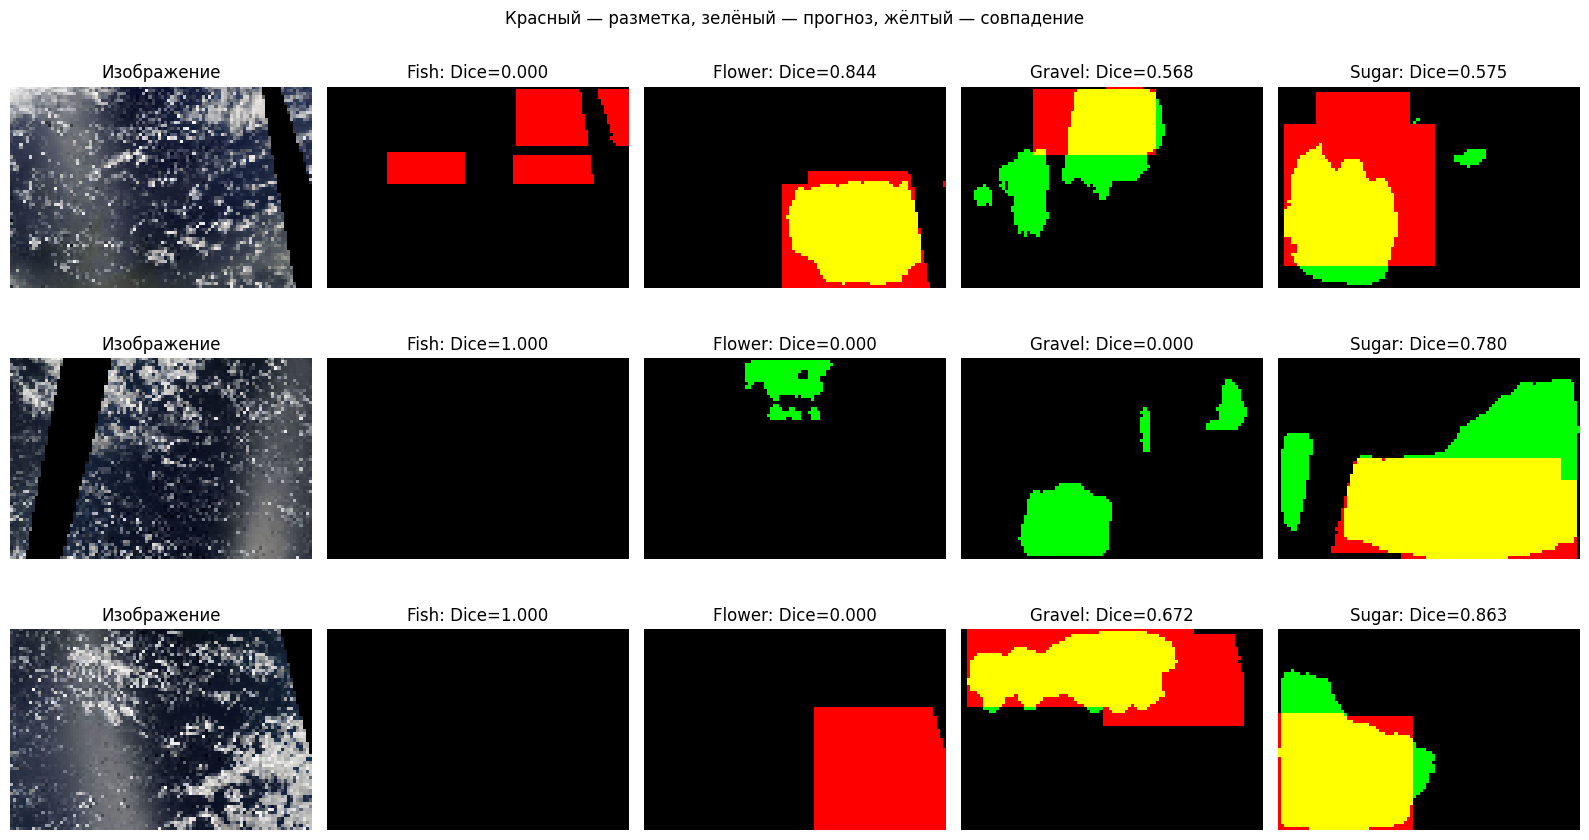

Лучшая эпоха: 11. Лучшие веса: cloud_cnn_best.pt
Итоговый Dice на 555 тестовых снимках: 0.5896; пустые маски: 0.4730


In [8]:
model.eval()
fig, axes = plt.subplots(3, 5, figsize=(16, 9))
for row in range(3):
    image, target = test_dataset[row]
    with torch.no_grad():
        logits = model(image.unsqueeze(0).to(device))
        prediction = (F.softmax(logits, dim=1)[:, 1] > thresholds).float()
        areas = prediction.sum(dim=(2, 3), keepdim=True) / (HEIGHT * WIDTH)
        prediction = (prediction * (areas >= min_areas).float())[0].cpu()
    rgb = np.zeros((HEIGHT, WIDTH, 3), dtype=np.float32)
    for c in range(3):
        rgb[:, :, c] = image[c].numpy()
    axes[row, 0].imshow(rgb)
    axes[row, 0].set_title('Изображение')
    axes[row, 0].axis('off')
    scores = dice_coefficient(prediction.unsqueeze(0), target.unsqueeze(0))[0]
    for c, class_name in enumerate(CLASSES):
        overlay = np.zeros((HEIGHT, WIDTH, 3), dtype=np.float32)
        overlay[:, :, 0] = target[c].numpy()
        overlay[:, :, 1] = prediction[c].numpy()
        axes[row, c + 1].imshow(overlay)
        axes[row, c + 1].set_title(f'{class_name}: Dice={scores[c].item():.3f}')
        axes[row, c + 1].axis('off')
plt.suptitle('Красный — разметка, зелёный — прогноз, жёлтый — совпадение')
plt.tight_layout()
plt.show()
print(f'Лучшая эпоха: {best_epoch}. Лучшие веса: {CHECKPOINT}')
print(f'Итоговый Dice на {len(test_dataset)} тестовых снимках: {test_dice:.4f}; пустые маски: {empty_dice:.4f}')